<a href="https://colab.research.google.com/github/AlvinManoj05/Parallel_project_Computer_Vision/blob/main/Parallel_Project__computerVision_PneumoniaDetection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

01_Dataset_Exploration_and_Preprocessing-Ananthika

Import Libraries

In [5]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import random
from PIL import Image
from sklearn.model_selection import train_test_split
import tensorflow as tf
from google.colab import drive


In [6]:
# 1. Clone the GitHub repository locally in Colab
!git clone https://github.com/AlvinManoj05/Parallel_project_Computer_Vision.git

# 2. Set the correct local dataset path
dataset_path = "/content/Parallel_project_Computer_Vision/xray_dataset_covid19"

# 3. Verify the path and list folders
print("Dataset exists:", os.path.exists(dataset_path))
if os.path.exists(dataset_path):
    print("Available folders:", os.listdir(dataset_path))

fatal: destination path 'Parallel_project_Computer_Vision' already exists and is not an empty directory.
Dataset exists: True
Available folders: ['test', 'single prediction', 'train']


In [7]:
#Count the images

classes = ["NORMAL", "PNEUMONIA"]

for split in ["train", "test"]:
    print(f"\n{split.upper()} DATASET")

    for class_name in classes:
        folder = os.path.join(dataset_path, split, class_name)

        images = [
            file for file in os.listdir(folder)
            if file.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        print(f"{class_name}: {len(images)} images")



TRAIN DATASET
NORMAL: 74 images
PNEUMONIA: 74 images

TEST DATASET
NORMAL: 20 images
PNEUMONIA: 20 images


Dataset Exploration – Image Visualization

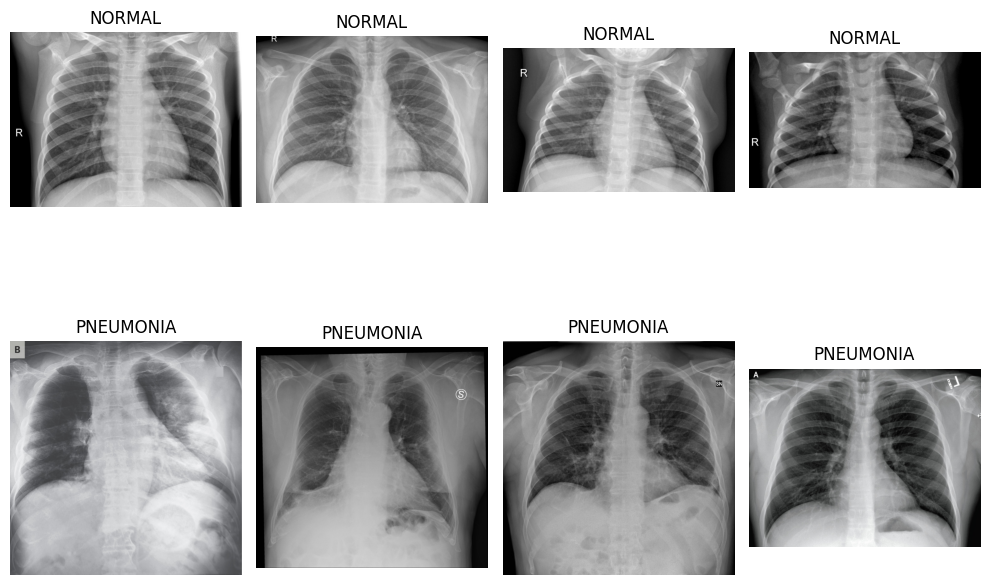

In [8]:
#Display NORMAL and PNEUMONIA images
classes = ["NORMAL", "PNEUMONIA"]

plt.figure(figsize=(10, 8))

for i, class_name in enumerate(classes):
    folder = os.path.join(dataset_path, "train", class_name)

    image_files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    sample_images = random.sample(image_files, min(4, len(image_files)))

    for j, image_name in enumerate(sample_images):
        image_path = os.path.join(folder, image_name)
        image = mpimg.imread(image_path)

        plt.subplot(2, 4, i * 4 + j + 1)
        plt.imshow(image, cmap="gray")
        plt.title(class_name)
        plt.axis("off")

plt.tight_layout()
plt.show()


In [9]:
#Image dimensions and formats
image_data = []

classes = ["NORMAL", "PNEUMONIA"]

for class_name in classes:
    folder = os.path.join(dataset_path, "train", class_name)

    for filename in os.listdir(folder):
        image_path = os.path.join(folder, filename)

        try:
            with Image.open(image_path) as img:
                image_data.append({
                    "Class": class_name,
                    "Filename": filename,
                    "Width": img.width,
                    "Height": img.height,
                    "Format": img.format,
                    "Mode": img.mode
                })

        except Exception as e:
            print("Error:", filename, e)

df = pd.DataFrame(image_data)

print("Total images inspected:", len(df))
print("\nImage dimensions:")
print(df[["Width", "Height"]].describe())

print("\nImage formats:")
print(df["Format"].value_counts())

print("\nImage modes:")
print(df["Mode"].value_counts())


Total images inspected: 148

Image dimensions:
             Width       Height
count   148.000000   148.000000
mean   1697.527027  1385.479730
std     767.623698   693.882888
min     255.000000   237.000000
25%    1246.750000   875.500000
50%    1790.500000  1376.500000
75%    2060.250000  1757.250000
max    4248.000000  4095.000000

Image formats:
Format
JPEG    136
PNG      12
Name: count, dtype: int64

Image modes:
Mode
L       81
RGB     56
RGBA    11
Name: count, dtype: int64


In [10]:
#Check for corrupted images
corrupted_images = []
checked_images = 0

for split in ["train", "test"]:
    for class_name in classes:

        folder = os.path.join(dataset_path, split, class_name)

        for filename in os.listdir(folder):
            image_path = os.path.join(folder, filename)

            try:
                with Image.open(image_path) as img:
                    img.verify()

                checked_images += 1

            except Exception:
                corrupted_images.append(image_path)

print("Images checked:", checked_images)
print("Corrupted images:", len(corrupted_images))
print("\nCorrupted file paths:")
print(corrupted_images)


Images checked: 188
Corrupted images: 0

Corrupted file paths:
[]


Train-validation split

In [11]:

image_paths = []
labels = []

class_names = ["NORMAL", "PNEUMONIA"]

for label, class_name in enumerate(class_names):

    folder = os.path.join(dataset_path, "train", class_name)

    for filename in os.listdir(folder):

        if filename.lower().endswith((".jpg", ".jpeg", ".png")):

            image_paths.append(os.path.join(folder, filename))
            labels.append(label)

# Split training data into training and validation
X_train, X_val, y_train, y_val = train_test_split(
    image_paths,
    labels,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))

print("\nTraining class distribution:")
for label, class_name in enumerate(class_names):
    print(class_name, ":", y_train.count(label))

print("\nValidation class distribution:")
for label, class_name in enumerate(class_names):
    print(class_name, ":", y_val.count(label))


Training images: 118
Validation images: 30

Training class distribution:
NORMAL : 59
PNEUMONIA : 59

Validation class distribution:
NORMAL : 15
PNEUMONIA : 15


Image resizing and normalization

In [12]:
IMG_SIZE = 224

def preprocess_images(image_paths):
    images = []

    for path in image_paths:
        img = Image.open(path).convert("L")
        img = img.resize((IMG_SIZE, IMG_SIZE))

        img_array = np.array(img, dtype=np.float32) / 255.0

        images.append(img_array)

    images = np.array(images)
    images = np.expand_dims(images, axis=-1)

    return images

# Preprocess training and validation images
X_train_processed = preprocess_images(X_train)
X_val_processed = preprocess_images(X_val)

# Convert labels into NumPy arrays
y_train = np.array(y_train, dtype=np.float32)
y_val = np.array(y_val, dtype=np.float32)

print("Training shape:", X_train_processed.shape)
print("Validation shape:", X_val_processed.shape)

print("Minimum pixel value:", X_train_processed.min())
print("Maximum pixel value:", X_train_processed.max())


Training shape: (118, 224, 224, 1)
Validation shape: (30, 224, 224, 1)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


Visualize preprocessed images

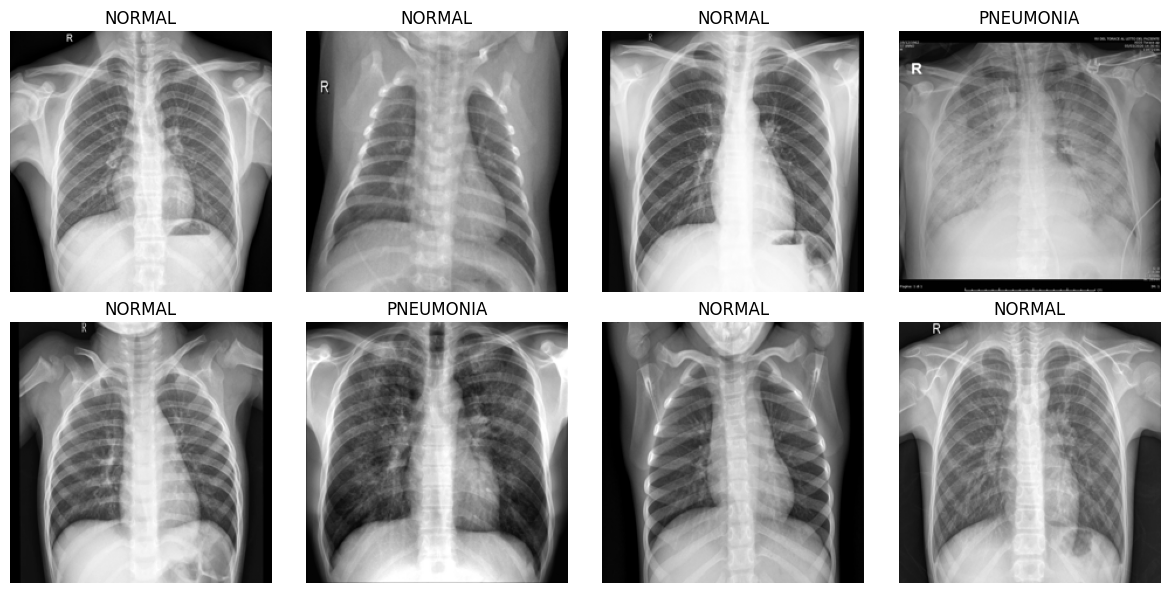

In [13]:
plt.figure(figsize=(12, 6))

for i in range(8):
    plt.subplot(2, 4, i + 1)

    plt.imshow(X_train_processed[i].squeeze(), cmap="gray")

    label = class_names[int(y_train[i])]
    plt.title(label)

    plt.axis("off")

plt.tight_layout()
plt.show()


Preprocess test images

In [14]:
test_paths = []
test_labels = []

class_names = ["NORMAL", "PNEUMONIA"]

for label, class_name in enumerate(class_names):

    folder = os.path.join(dataset_path, "test", class_name)

    for filename in os.listdir(folder):

        if filename.lower().endswith((".jpg", ".jpeg", ".png")):

            test_paths.append(os.path.join(folder, filename))
            test_labels.append(label)

# Preprocess test images
X_test_processed = preprocess_images(test_paths)

y_test = np.array(test_labels, dtype=np.float32)

print("Test images:", len(X_test_processed))
print("Test shape:", X_test_processed.shape)

print("\nTest class distribution:")

for i, name in enumerate(class_names):
    print(name, ":", np.sum(y_test == i))


Test images: 40
Test shape: (40, 224, 224, 1)

Test class distribution:
NORMAL : 20
PNEUMONIA : 20


Verify all datasets

In [15]:
print("FINAL DATASET SHAPES")

print("Training:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Testing:", X_test_processed.shape)

print("\nLabel shapes")

print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)
print("Testing labels:", y_test.shape)


FINAL DATASET SHAPES
Training: (118, 224, 224, 1)
Validation: (30, 224, 224, 1)
Testing: (40, 224, 224, 1)

Label shapes
Training labels: (118,)
Validation labels: (30,)
Testing labels: (40,)


Convert images into TensorFlow datasets

In [16]:
BATCH_SIZE = 16

# Training dataset
train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train_processed, y_train)
)

train_dataset = (
    train_dataset
    .shuffle(buffer_size=len(X_train_processed), seed=42)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Validation dataset
val_dataset = tf.data.Dataset.from_tensor_slices(
    (X_val_processed, y_val)
)

val_dataset = (
    val_dataset
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Testing dataset
test_dataset = tf.data.Dataset.from_tensor_slices(
    (X_test_processed, y_test)
)

test_dataset = (
    test_dataset
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("TensorFlow datasets created successfully!")

print("Training batches:", len(train_dataset))
print("Validation batches:", len(val_dataset))
print("Testing batches:", len(test_dataset))


TensorFlow datasets created successfully!
Training batches: 8
Validation batches: 2
Testing batches: 3


In [17]:
for images, labels in train_dataset.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Image data type:", images.dtype)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())


Image batch shape: (16, 224, 224, 1)
Label batch shape: (16,)
Image data type: <dtype: 'float32'>
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [18]:
save_path = "/content/preprocessed_data"
os.makedirs(save_path, exist_ok=True)

np.save(save_path + "/X_train.npy", X_train_processed)
np.save(save_path + "/y_train.npy", y_train)
np.save(save_path + "/X_val.npy", X_val_processed)
np.save(save_path + "/y_val.npy", y_val)
np.save(save_path + "/X_test.npy", X_test_processed)
np.save(save_path + "/y_test.npy", y_test)

print("Saved inside Colab successfully!")

Saved inside Colab successfully!


##Model Development-CNN-Anjima



**Import libraries**


In [19]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

In [20]:
#check input data
print("Training images:", X_train_processed.shape)
print("Validation images:", X_val_processed.shape)

print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)

Training images: (118, 224, 224, 1)
Validation images: (30, 224, 224, 1)
Training labels: (118,)
Validation labels: (30,)


In [21]:
#check shape of test images and test labels
print("Test images:", X_test_processed.shape)
print("Test labels:", y_test.shape)

Test images: (40, 224, 224, 1)
Test labels: (40,)


**CNN Model**

In [22]:
cnn_model = models.Sequential([
layers.Input(shape=(224, 224, 1)),
layers.Conv2D(32, (3,3), activation='relu', padding='same'),
layers.MaxPooling2D(2,2),

layers.Conv2D(64, (3,3), activation='relu', padding='same'),
layers.MaxPooling2D(2,2),

layers.Conv2D(128, (3,3), activation='relu', padding='same'),
layers.MaxPooling2D(2,2),

layers.GlobalAveragePooling2D(),

layers.Dense(128, activation='relu'),

layers.Dropout(0.5),

layers.Dense(1, activation='sigmoid')])

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,313 (427.00 KB)

 Trainable params: 109,313 (427.00 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
#compile the model
cnn_model.compile(optimizer='adam',loss='binary_crossentropy',metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')])

In [24]:
#train the model
early_stop_cnn = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True)
cnn_history = cnn_model.fit(
 X_train_processed,y_train,
validation_data=(X_val_processed, y_val),epochs=20,batch_size=16,callbacks=[early_stop_cnn])

Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 24s 2s/step - accuracy: 0.4915 - auc: 0.3979 - loss: 0.7058 - precision: 0.3333 - recall: 0.0169 - val_accuracy: 0.5000 - val_auc: 0.6156 - val_loss: 0.6932 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.5000 - auc: 0.4739 - loss: 0.6936 - precision: 0.5000 - recall: 0.1017 - val_accuracy: 0.5000 - val_auc: 0.5000 - val_loss: 0.6929 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.6017 - auc: 0.5865 - loss: 0.6919 - precision: 0.5769 - recall: 0.7627 - val_accuracy: 0.5000 - val_auc: 0.6333 - val_loss: 0.6927 - val_precision: 0.5000 - val_recall: 1.0000
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.4746 - auc: 0.4377 - loss: 0.6950 - precision: 0.4615 - recall: 0.3051 - val_accuracy: 0.5000 - val_auc: 0.5333 - val_loss: 0.6921 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 5/20
8/8 ━━━━━━

In [25]:
#save the model
cnn_model.save("custom_cnn.keras")

# Fine Tuning Custom CNN - Dhevan


In [26]:
# ==========================================
# CUSTOM CNN FINE-TUNING
# ==========================================

# Load the saved baseline Custom CNN model
cnn_finetuned = tf.keras.models.load_model("custom_cnn.keras")

# Optional: Freeze the first convolutional block (Conv2D + MaxPooling2D)
# and fine-tune the deeper layers. Comment out these 2 lines to train all layers.
for layer in cnn_finetuned.layers[:2]:
    layer.trainable = False

# Recompile with a much lower learning rate for fine-tuning
cnn_finetuned.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc"),
    ],
)

cnn_finetuned.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,313 (427.00 KB)

 Trainable params: 108,993 (425.75 KB)

 Non-trainable params: 320 (1.25 KB)

In [27]:
early_stop_cnn_ft = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
)

reduce_lr_cnn_ft = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-7,
)

cnn_finetune_history = cnn_finetuned.fit(
    X_train_processed,
    y_train,
    validation_data=(X_val_processed, y_val),
    epochs=15,
    batch_size=16,
    callbacks=[early_stop_cnn_ft, reduce_lr_cnn_ft],
)

# Save the fine-tuned Custom CNN
cnn_finetuned.save("custom_cnn_finetuned.keras")
print("Fine-tuned Custom CNN saved successfully!")

Epoch 1/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 614ms/step - accuracy: 0.8051 - auc: 0.8294 - loss: 0.5023 - precision: 0.7903 - recall: 0.8305 - val_accuracy: 0.8333 - val_auc: 0.9267 - val_loss: 0.4111 - val_precision: 0.8571 - val_recall: 0.8000 - learning_rate: 1.0000e-04
Epoch 2/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.7966 - auc: 0.8424 - loss: 0.4960 - precision: 0.7869 - recall: 0.8136 - val_accuracy: 0.8333 - val_auc: 0.9267 - val_loss: 0.4099 - val_precision: 0.8571 - val_recall: 0.8000 - learning_rate: 1.0000e-04
Epoch 3/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.7881 - auc: 0.8344 - loss: 0.5037 - precision: 0.7833 - recall: 0.7966 - val_accuracy: 0.8333 - val_auc: 0.9267 - val_loss: 0.4099 - val_precision: 0.8571 - val_recall: 0.8000 - learning_rate: 1.0000e-04
Epoch 4/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.8051 - auc: 0.8641 - loss: 0.4672 - precision: 0.8000 - recall: 0.8136 - val_accuracy: 0.8333 - val_auc: 0.9267 - val_loss: 0.4090 - va

In [28]:
# Evaluate on test data
ft_cnn_results = cnn_finetuned.evaluate(
    X_test_processed,
    y_test,
    batch_size=16,
    verbose=1,
)

print("\nFINE-TUNED CUSTOM CNN TEST RESULTS")
for name, value in zip(cnn_finetuned.metrics_names, ft_cnn_results):
    print(f"{name}: {value:.4f}")

# Generate predictions and classification report
ft_cnn_prob = cnn_finetuned.predict(X_test_processed)
ft_cnn_pred = (ft_cnn_prob > 0.5).astype(int).flatten()

print("\nFINE-TUNED CUSTOM CNN CLASSIFICATION REPORT")
print(
    classification_report(
        y_test.astype(int),
        ft_cnn_pred,
        target_names=["NORMAL", "PNEUMONIA"],
        digits=4,
    )
)

3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 1s/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.1841 - precision: 1.0000 - recall: 1.0000

FINE-TUNED CUSTOM CNN TEST RESULTS
loss: 0.1841
compile_metrics: 1.0000
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 388ms/step

FINE-TUNED CUSTOM CNN CLASSIFICATION REPORT
              precision    recall  f1-score   support

      NORMAL     1.0000    1.0000    1.0000        20
   PNEUMONIA     1.0000    1.0000    1.0000        20

    accuracy                         1.0000        40
   macro avg     1.0000    1.0000    1.0000        40
weighted avg     1.0000    1.0000    1.0000        40



#Model development-Transfer learning-Ashwathy

**Transfer Learning-ResNet-50**

In [29]:
base_model = ResNet50(weights='imagenet',include_top=False,input_shape=(224, 224, 3))
base_model.trainable = False

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [30]:
#adding classification layers
inputs = layers.Input(shape=(224, 224, 1))
# Convert grayscale to 3 channels
x = layers.Lambda(lambda img: tf.image.grayscale_to_rgb(img))(inputs)
# Convert pixel values from 0-1 to 0-255
x = layers.Rescaling(255.0)(x)
# Apply ResNet50 preprocessing
x = layers.Lambda(preprocess_input)(x)
# Extract image features
x = base_model(x, training=False)
# Classification layers
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(1, activation='sigmoid')(x)
transfer_model = models.Model(inputs, outputs)
transfer_model.summary()

Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,113 (90.98 MB)

 Trainable params: 262,401 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [31]:
#compile the model
transfer_model.compile(
optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
loss='binary_crossentropy',metrics=['accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')])

In [32]:
#train the model
early_stop_transfer = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True)
transfer_history = transfer_model.fit(X_train_processed,y_train,
validation_data=(X_val_processed, y_val),epochs=10,batch_size=16,
callbacks=[early_stop_transfer])

Epoch 1/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 59s 5s/step - accuracy: 0.5508 - auc: 0.5475 - loss: 0.8121 - precision: 0.5405 - recall: 0.6780 - val_accuracy: 0.8333 - val_auc: 0.9911 - val_loss: 0.4225 - val_precision: 1.0000 - val_recall: 0.6667
Epoch 2/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 91ms/step - accuracy: 0.7881 - auc: 0.8815 - loss: 0.4716 - precision: 0.8864 - recall: 0.6610 - val_accuracy: 0.9667 - val_auc: 0.9978 - val_loss: 0.2586 - val_precision: 0.9375 - val_recall: 1.0000
Epoch 3/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 86ms/step - accuracy: 0.8475 - auc: 0.9378 - loss: 0.3527 - precision: 0.8154 - recall: 0.8983 - val_accuracy: 0.9667 - val_auc: 1.0000 - val_loss: 0.2149 - val_precision: 0.9375 - val_recall: 1.0000
Epoch 4/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 91ms/step - accuracy: 0.9068 - auc: 0.9832 - loss: 0.2350 - precision: 0.9000 - recall: 0.9153 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.1459 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 5/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 88ms/s

In [33]:
#save the model
transfer_model.save("resnet50_transfer.keras")

**Finetuning**

In [34]:
base_model.trainable = True
# Freeze all layers except the last 30
for layer in base_model.layers[:-30]:
    layer.trainable = False
# Keep Batch Normalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

In [35]:
#recompile the model
transfer_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),loss='binary_crossentropy',
metrics=['accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')])

# Hyperparameter Tuning – ResNet50 - Jobil

In [53]:
!pip install -q keras-tuner

import time
import warnings
import keras_tuner as kt
from tensorflow.keras import regularizers
from sklearn.utils.class_weight import compute_class_weight

# harmless message when weights are reloaded into a re-compiled model (optimizer state is simply reset)
warnings.filterwarnings("ignore", message="Skipping variable loading for optimizer")

SEED = 42
tf.keras.utils.set_random_seed(SEED)

TUNE_DIR = "/content/tuner_logs"

# ---- Search budget (lower these for a quick test run) ----
N_TRIALS_RESNET   = 8    # random configurations tried for ResNet50 (frozen phase)
RESNET_SEARCH_EPOCHS = 8
FT_EPOCHS         = 5    # epochs per fine-tuning grid run
FINAL_EPOCHS      = 30   # max epochs when retraining the winners

# Class weights computed from the TRAINING labels only (data is imbalanced)
_cw = compute_class_weight("balanced", classes=np.array([0.0, 1.0]), y=y_train)
TUNE_CLASS_WEIGHT = {0: float(_cw[0]), 1: float(_cw[1])}
print("Balanced class weights:", TUNE_CLASS_WEIGHT)

def tune_metrics():
    # fresh metric objects for every model
    return ["accuracy",
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.AUC(name="auc")]

def tune_results_table(tuner, n=5):
    """Top-n trials as a DataFrame (hyperparameters + best val AUC)."""
    rows = []
    for t in tuner.oracle.get_best_trials(n):
        row = dict(t.hyperparameters.values)
        row["val_auc"] = t.score
        rows.append(row)
    return pd.DataFrame(rows)

Balanced class weights: {0: 1.0, 1: 1.0}


## Tuning ResNet50 (Transfer Learning + Fine-tuning)

In [54]:
class ResNetHyperModel(kt.HyperModel):
    """Same pipeline as the original ResNet50 transfer model (grayscale->RGB, rescale, preprocess_input,
    frozen ResNet50, GAP, Dense, Dropout, Sigmoid) with the head hyperparameters exposed."""

    def build(self, hp):
        tune_base = ResNet50(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
        tune_base.trainable = False

        units   = hp.Choice("dense_units", [64, 128, 256, 512])
        l2      = hp.Choice("l2", [0.0, 1e-5, 1e-4, 1e-3])
        dropout = hp.Float("dropout", 0.2, 0.6, step=0.1)
        lr      = hp.Float("learning_rate", 1e-5, 1e-3, sampling="log")

        inputs = layers.Input(shape=(224, 224, 1))
        x = layers.Lambda(lambda img: tf.image.grayscale_to_rgb(img))(inputs)
        x = layers.Rescaling(255.0)(x)
        x = layers.Lambda(preprocess_input)(x)
        x = tune_base(x, training=False)
        x = layers.GlobalAveragePooling2D()(x)
        x = layers.Dense(units, activation="relu",
                         kernel_regularizer=regularizers.l2(l2) if l2 > 0 else None)(x)
        x = layers.Dropout(dropout)(x)
        outputs = layers.Dense(1, activation="sigmoid")(x)
        model = models.Model(inputs, outputs)

        model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                      loss="binary_crossentropy",
                      metrics=tune_metrics())
        return model

    def fit(self, hp, model, *args, **kwargs):
        batch_size = hp.Choice("batch_size", [16, 32])
        use_cw     = hp.Boolean("use_class_weight")
        return model.fit(*args,
                         batch_size=batch_size,
                         class_weight=TUNE_CLASS_WEIGHT if use_cw else None,
                         **kwargs)

In [55]:
# ---------- Stage A: head hyperparameters (base frozen) ----------
resnet_tuner = kt.RandomSearch(
    ResNetHyperModel(),
    objective=kt.Objective("val_auc", direction="max"),
    max_trials=N_TRIALS_RESNET,
    executions_per_trial=1,
    directory=TUNE_DIR,
    project_name="resnet_search",
    overwrite=True,
    seed=SEED
)

resnet_tuner.search(
    X_train_processed, y_train,
    validation_data=(X_val_processed, y_val),
    epochs=RESNET_SEARCH_EPOCHS,
    callbacks=[EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)]
)

print("\nTop ResNet50 head configurations (by validation AUC):")
tune_results_table(resnet_tuner, n=5)

Trial 8 Complete [00h 00m 44s]
val_auc: 0.6377777457237244

Best val_auc So Far: 1.0000001192092896
Total elapsed time: 00h 07m 03s

Top ResNet50 head configurations (by validation AUC):


,dense_units,l2,dropout,learning_rate,batch_size,use_class_weight,val_auc
0,512,0.00001,0.2,0.000036,32,False,1.000000
1,256,0.00000,0.3,0.000035,16,False,1.000000
2,512,0.00001,0.4,0.000014,16,False,1.000000
3,256,0.00000,0.3,0.000097,32,False,1.000000
4,128,0.00001,0.2,0.000014,32,True,0.982222


In [56]:
# ---------- Train the best Stage A model, keep its weights as the fine-tuning starting point ----------
tuned_resnet_hp = resnet_tuner.get_best_hyperparameters(1)[0]
print("Best ResNet50 head hyperparameters:")
for k, v in tuned_resnet_hp.values.items():
    print(f"  {k}: {v}")

tuned_resnet = resnet_tuner.hypermodel.build(tuned_resnet_hp)
tuned_resnet_cw = TUNE_CLASS_WEIGHT if tuned_resnet_hp.get("use_class_weight") else None

tuned_resnet_head_history = tuned_resnet.fit(
    X_train_processed, y_train,
    validation_data=(X_val_processed, y_val),
    epochs=10,
    batch_size=tuned_resnet_hp.get("batch_size"),
    class_weight=tuned_resnet_cw,
    callbacks=[EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)]
)

TUNE_HEAD_WEIGHTS = "/content/resnet_tuned_head.weights.h5"
tuned_resnet.save_weights(TUNE_HEAD_WEIGHTS)

# the ResNet50 sub-model inside tuned_resnet
tuned_resnet_base = [l for l in tuned_resnet.layers if isinstance(l, tf.keras.Model)][0]

def tune_set_finetuning(n_unfreeze, lr):
    """Unfreeze the last n_unfreeze ResNet layers (BatchNorm stays frozen) and recompile."""
    tuned_resnet_base.trainable = True
    for layer in tuned_resnet_base.layers[:-n_unfreeze]:
        layer.trainable = False
    for layer in tuned_resnet_base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    tuned_resnet.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                         loss="binary_crossentropy",
                         metrics=tune_metrics())

Best ResNet50 head hyperparameters:
  dense_units: 512
  l2: 1e-05
  dropout: 0.2
  learning_rate: 3.6276965095376624e-05
  batch_size: 32
  use_class_weight: False
Epoch 1/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 25s 4s/step - accuracy: 0.4576 - auc: 0.4573 - loss: 0.7967 - precision: 0.4576 - recall: 0.4576 - val_accuracy: 0.6000 - val_auc: 0.5933 - val_loss: 0.6928 - val_precision: 0.6667 - val_recall: 0.4000
Epoch 2/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 191ms/step - accuracy: 0.6864 - auc: 0.7588 - loss: 0.6070 - precision: 0.7500 - recall: 0.5593 - val_accuracy: 0.8333 - val_auc: 0.8867 - val_loss: 0.5235 - val_precision: 1.0000 - val_recall: 0.6667
Epoch 3/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 185ms/step - accuracy: 0.8220 - auc: 0.9144 - loss: 0.4461 - precision: 0.8654 - recall: 0.7627 - val_accuracy: 0.9000 - val_auc: 0.9600 - val_loss: 0.4031 - val_precision: 0.9286 - val_recall: 0.8667
Epoch 4/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 185ms/step - accuracy: 0.9237 - auc: 0.9813 - loss: 0.3027 - precision: 0.9310

In [57]:
# ---------- Stage B: fine-tuning grid search ----------
tune_ft_rows = []

for n_unfreeze in [20, 30, 50]:
    for ft_lr in [1e-5, 3e-6]:
        start = time.time()
        tuned_resnet.load_weights(TUNE_HEAD_WEIGHTS)      # always restart from the same point
        tune_set_finetuning(n_unfreeze, ft_lr)

        tuned_resnet.fit(
            X_train_processed, y_train,
            validation_data=(X_val_processed, y_val),
            epochs=FT_EPOCHS,
            batch_size=tuned_resnet_hp.get("batch_size"),
            class_weight=tuned_resnet_cw,
            callbacks=[EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)],
            verbose=0
        )
        res = tuned_resnet.evaluate(X_val_processed, y_val, verbose=0, return_dict=True)
        tune_ft_rows.append({"unfrozen_layers": n_unfreeze, "ft_learning_rate": ft_lr,
                             "val_auc": res["auc"], "val_loss": res["loss"],
                             "val_recall": res["recall"], "val_precision": res["precision"]})
        print(f"unfreeze={n_unfreeze:>2} lr={ft_lr:.0e} -> val_auc={res['auc']:.4f} "
              f"val_loss={res['loss']:.4f} ({time.time()-start:.0f}s)")

tune_ft_df = pd.DataFrame(tune_ft_rows).sort_values("val_auc", ascending=False).reset_index(drop=True)
tune_ft_df

unfreeze=20 lr=1e-05 -> val_auc=1.0000 val_loss=0.0367 (37s)
unfreeze=20 lr=3e-06 -> val_auc=1.0000 val_loss=0.0917 (33s)
unfreeze=30 lr=1e-05 -> val_auc=1.0000 val_loss=0.0365 (31s)
unfreeze=30 lr=3e-06 -> val_auc=1.0000 val_loss=0.0898 (30s)
unfreeze=50 lr=1e-05 -> val_auc=1.0000 val_loss=0.0383 (35s)
unfreeze=50 lr=3e-06 -> val_auc=1.0000 val_loss=0.0902 (33s)


,unfrozen_layers,ft_learning_rate,val_auc,val_loss,val_recall,val_precision
0,20,0.000010,1.0,0.036651,1.0,1.0
1,30,0.000010,1.0,0.036502,1.0,1.0
2,50,0.000010,1.0,0.038296,1.0,1.0
3,20,0.000003,1.0,0.091663,1.0,1.0
4,30,0.000003,1.0,0.089774,1.0,1.0
5,50,0.000003,1.0,0.090231,1.0,1.0


In [58]:
# ---------- Retrain the best fine-tuning setting for longer and save ----------
best_ft = tune_ft_df.iloc[0]
print(f"Best fine-tuning setting: unfreeze last {int(best_ft['unfrozen_layers'])} layers, "
      f"learning rate {best_ft['ft_learning_rate']:.0e}")

tuned_resnet.load_weights(TUNE_HEAD_WEIGHTS)
tune_set_finetuning(int(best_ft["unfrozen_layers"]), float(best_ft["ft_learning_rate"]))

tuned_resnet_history = tuned_resnet.fit(
    X_train_processed, y_train,
    validation_data=(X_val_processed, y_val),
    epochs=FINAL_EPOCHS,
    batch_size=tuned_resnet_hp.get("batch_size"),
    class_weight=tuned_resnet_cw,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7)
    ]
)

tuned_resnet.save("resnet50_tuned_finetuned.keras")
print("\nValidation results (tuned ResNet50):")
tuned_resnet_val = tuned_resnet.evaluate(X_val_processed, y_val, verbose=0, return_dict=True)
print({k: round(v, 4) for k, v in tuned_resnet_val.items()})

Best fine-tuning setting: unfreeze last 20 layers, learning rate 1e-05
Epoch 1/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 27s 4s/step - accuracy: 0.9661 - auc: 0.9974 - loss: 0.1336 - precision: 0.9508 - recall: 0.9831 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.1110 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 2/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 210ms/step - accuracy: 0.9915 - auc: 0.9994 - loss: 0.0865 - precision: 1.0000 - recall: 0.9831 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0832 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 3/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 197ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0593 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0640 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 4/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 206ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0361 - precision: 1.0000 - recall:

## Final result of the hyperparameter tuned ResNet50

In [59]:
test_res = tuned_resnet.evaluate(X_test_processed, y_test, batch_size=16, verbose=0, return_dict=True)

tuned_summary_df = pd.DataFrame([{
    "Model": "Tuned ResNet50",
    "Val AUC": tuned_resnet_val["auc"],
    "Test accuracy": test_res["accuracy"],
    "Test precision": test_res["precision"],
    "Test recall": test_res["recall"],
    "Test AUC": test_res["auc"],
}]).round(4)
tuned_summary_df

,Model,Val AUC,Test accuracy,Test precision,Test recall,Test AUC
0,Tuned ResNet50,1.0,0.975,1.0,0.95,1.0


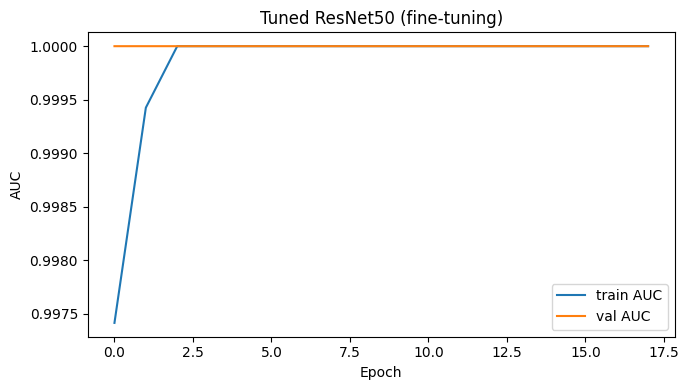

In [60]:
# Training curves of the tuned ResNet50 (fine-tuning stage)
plt.figure(figsize=(7, 4))
plt.plot(tuned_resnet_history.history["auc"], label="train AUC")
plt.plot(tuned_resnet_history.history["val_auc"], label="val AUC")
plt.title("Tuned ResNet50 (fine-tuning)")
plt.xlabel("Epoch")
plt.ylabel("AUC")
plt.legend()
plt.tight_layout()
plt.show()

# Hyperparameter Tuning - Custom CNN - Alvin Manoj

In [62]:
!pip install -q keras-tuner

import keras_tuner as kt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

In [64]:
# Check existing data
print("Training data:", X_train_processed.shape)
print("Validation data:", X_val_processed.shape)
print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)


Training data: (118, 224, 224, 1)
Validation data: (30, 224, 224, 1)
Training labels: (118,)
Validation labels: (30,)


In [65]:
# Create tunable CNN
def build_tuned_cnn(hp):
 model = models.Sequential()
 filters_1 = hp.Choice("filters_1", [32, 64])
 model.add(layers.Conv2D(filters_1, (3, 3), activation="relu",
 input_shape=(224, 224, 1)))
 model.add(layers.MaxPooling2D((2, 2)))
 filters_2 = hp.Choice("filters_2", [64, 128])
 model.add(layers.Conv2D(filters_2, (3, 3), activation="relu"))
 model.add(layers.MaxPooling2D((2, 2)))
 filters_3 = hp.Choice("filters_3", [128, 256])
 model.add(layers.Conv2D(filters_3, (3, 3), activation="relu"))
 model.add(layers.MaxPooling2D((2, 2)))
 model.add(layers.GlobalAveragePooling2D())
 dense_units = hp.Choice("dense_units", [64, 128, 256])
 model.add(layers.Dense(dense_units, activation="relu"))
 dropout_rate = hp.Choice("dropout_rate", [0.3, 0.4, 0.5])
 model.add(layers.Dropout(dropout_rate))
 model.add(layers.Dense(1, activation="sigmoid"))
 learning_rate = hp.Choice("learning_rate", [1e-4, 5e-4, 1e-3])
 model.compile(
 optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
 loss="binary_crossentropy",
 metrics=[
 "accuracy",
 tf.keras.metrics.Precision(name="precision"),
 tf.keras.metrics.Recall(name="recall"),
 tf.keras.metrics.AUC(name="auc")
 ]
 )
 return model


In [66]:
# Test model
test_model = build_tuned_cnn(kt.HyperParameters())
test_model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,993 (394.50 KB)

 Trainable params: 100,993 (394.50 KB)

 Non-trainable params: 0 (0.00 B)

In [68]:
# Create tuner
tuner = kt.RandomSearch(
 build_tuned_cnn,
 objective=kt.Objective("val_auc", direction="max"),
 max_trials=10,
 executions_per_trial=1,
 directory="pneumonia_tuning",
 project_name="custom_cnn",
 overwrite=True
)


In [69]:
# Show search space
tuner.search_space_summary()

Search space summary
Default search space size: 6
filters_1 (Choice)
{'default': 32, 'conditions': [], 'values': [32, 64], 'ordered': True}
filters_2 (Choice)
{'default': 64, 'conditions': [], 'values': [64, 128], 'ordered': True}
filters_3 (Choice)
{'default': 128, 'conditions': [], 'values': [128, 256], 'ordered': True}
dense_units (Choice)
{'default': 64, 'conditions': [], 'values': [64, 128, 256], 'ordered': True}
dropout_rate (Choice)
{'default': 0.3, 'conditions': [], 'values': [0.3, 0.4, 0.5], 'ordered': True}
learning_rate (Choice)
{'default': 0.0001, 'conditions': [], 'values': [0.0001, 0.0005, 0.001], 'ordered': True}


In [70]:
#  Early stopping
early_stop = EarlyStopping(
 monitor="val_loss",
 patience=5,
 restore_best_weights=True
)


In [71]:
# Start tuning
tuner.search(
 X_train_processed,
 y_train,
 validation_data=(X_val_processed, y_val),
 epochs=20,
 batch_size=16,
 callbacks=[early_stop]
)


Trial 10 Complete [00h 00m 37s]
val_auc: 0.991111159324646

Best val_auc So Far: 1.0
Total elapsed time: 00h 06m 16s


In [72]:
# Show results
tuner.results_summary()


Results summary
Results in pneumonia_tuning/custom_cnn
Showing 10 best trials
Objective(name="val_auc", direction="max")

Trial 01 summary
Hyperparameters:
filters_1: 32
filters_2: 128
filters_3: 256
dense_units: 256
dropout_rate: 0.5
learning_rate: 0.0005
Score: 1.0

Trial 07 summary
Hyperparameters:
filters_1: 32
filters_2: 64
filters_3: 256
dense_units: 128
dropout_rate: 0.3
learning_rate: 0.001
Score: 1.0

Trial 00 summary
Hyperparameters:
filters_1: 64
filters_2: 128
filters_3: 256
dense_units: 128
dropout_rate: 0.3
learning_rate: 0.001
Score: 0.9955555200576782

Trial 09 summary
Hyperparameters:
filters_1: 32
filters_2: 128
filters_3: 128
dense_units: 128
dropout_rate: 0.3
learning_rate: 0.0005
Score: 0.991111159324646

Trial 02 summary
Hyperparameters:
filters_1: 32
filters_2: 64
filters_3: 128
dense_units: 64
dropout_rate: 0.4
learning_rate: 0.001
Score: 0.9866666793823242

Trial 04 summary
Hyperparameters:
filters_1: 32
filters_2: 128
filters_3: 256
dense_units: 128
dropout_ra

In [73]:
# Get best hyperparameters
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
print("BEST HYPERPARAMETERS")
print("====================")
print("Filters 1:", best_hp.get("filters_1"))
print("Filters 2:", best_hp.get("filters_2"))
print("Filters 3:", best_hp.get("filters_3"))
print("Dense units:", best_hp.get("dense_units"))
print("Dropout:", best_hp.get("dropout_rate"))
print("Learning rate:", best_hp.get("learning_rate"))

BEST HYPERPARAMETERS
Filters 1: 32
Filters 2: 128
Filters 3: 256
Dense units: 256
Dropout: 0.5
Learning rate: 0.0005


In [74]:
# Get best model
best_cnn = tuner.get_best_models(num_models=1)[0]
best_cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 128)  │        36,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 398,529 (1.52 MB)

 Trainable params: 398,529 (1.52 MB)

 Non-trainable params: 0 (0.00 B)

In [75]:
# Train best model
best_history = best_cnn.fit(
 X_train_processed,
 y_train,
 validation_data=(X_val_processed, y_val),
 epochs=30,
 batch_size=16,
 callbacks=[early_stop]
)


Epoch 1/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.7881 - auc: 0.8528 - loss: 0.4800 - precision: 0.7833 - recall: 0.7966 - val_accuracy: 0.9000 - val_auc: 0.9733 - val_loss: 0.3859 - val_precision: 0.8750 - val_recall: 0.9333
Epoch 2/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.8898 - auc: 0.9325 - loss: 0.3959 - precision: 0.8966 - recall: 0.8814 - val_accuracy: 0.9333 - val_auc: 1.0000 - val_loss: 0.3357 - val_precision: 1.0000 - val_recall: 0.8667
Epoch 3/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.8814 - auc: 0.9558 - loss: 0.3551 - precision: 0.8689 - recall: 0.8983 - val_accuracy: 0.9000 - val_auc: 1.0000 - val_loss: 0.3424 - val_precision: 1.0000 - val_recall: 0.8000
Epoch 4/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - accuracy: 0.8305 - auc: 0.9283 - loss: 0.3705 - precision: 0.8421 - recall: 0.8136 - val_accuracy: 0.9000 - val_auc: 1.0000 - val_loss: 0.3129 - val_precision: 0.8333 - val_recall: 1.0000
Epoch 5/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/s

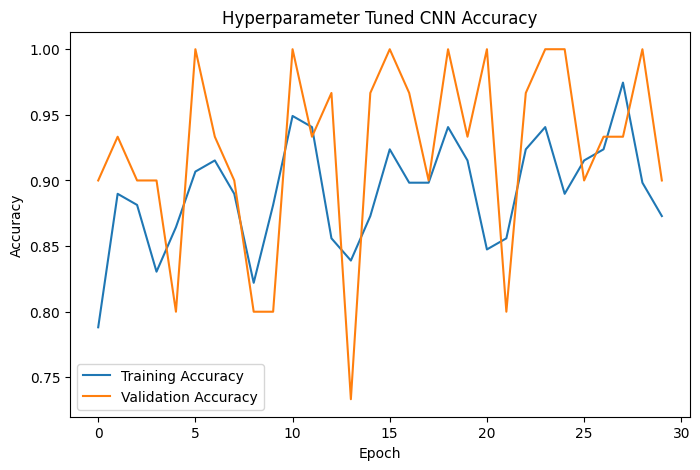

In [76]:
# Plot accuracy
plt.figure(figsize=(8, 5))
plt.plot(best_history.history["accuracy"], label="Training Accuracy")
plt.plot(best_history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Hyperparameter Tuned CNN Accuracy")
plt.legend()
plt.show()


Text(0.5, 1.0, 'Hyperparameter Tuned CNN Loss')

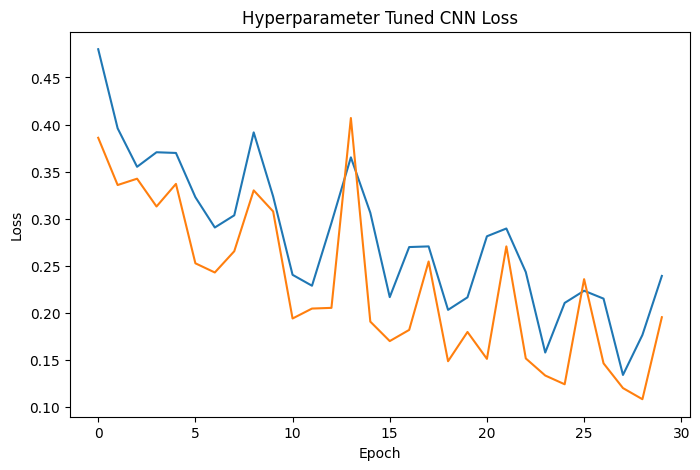

In [77]:
# Plot loss
plt.figure(figsize=(8, 5))
plt.plot(best_history.history["loss"], label="Training Loss")
plt.plot(best_history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Hyperparameter Tuned CNN Loss")
plt.legend()
plt.show()


In [78]:
# Save model
best_cnn.save("hyperparameter_tuned_cnn.keras")
print("Tuned CNN model saved successfully.")

Tuned CNN model saved successfully.


In [80]:
# Prepare test data
test_image_paths = []
test_labels = []
class_names = ["NORMAL", "PNEUMONIA"]
for label, class_name in enumerate(class_names):
  folder = os.path.join(dataset_path, "test", class_name)
  for filename in os.listdir(folder):
    if filename.lower().endswith((".jpg", ".jpeg", ".png")):
      test_image_paths.append(os.path.join(folder, filename))
      test_labels.append(label)


In [81]:
#  Preprocess test images
X_test_processed = preprocess_images(test_image_paths)
y_test = np.array(test_labels, dtype=np.float32)
print("Test shape:", X_test_processed.shape)
print("Test labels:", y_test.shape)


Test shape: (40, 224, 224, 1)
Test labels: (40,)


In [82]:
# Evaluate tuned CNN
test_results = best_cnn.evaluate(
 X_test_processed,
 y_test,
 verbose=1
)

2/2 ━━━━━━━━━━━━━━━━━━━━ 8s 4s/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0630 - precision: 1.0000 - recall: 1.0000


In [83]:
#  Print test metrics
print("\nFINAL TEST RESULTS")
print("==================")
print("Test Loss :", test_results[0])
print("Test Accuracy :", test_results[1])
print("Test Precision :", test_results[2])
print("Test Recall :", test_results[3])
print("Test AUC :", test_results[4])


FINAL TEST RESULTS
Test Loss : 0.0630301833152771
Test Accuracy : 1.0
Test Precision : 1.0
Test Recall : 1.0
Test AUC : 1.0


In [84]:
# Calculate F1
from sklearn.metrics import f1_score
y_pred_prob = best_cnn.predict(X_test_processed)
y_pred = (y_pred_prob >= 0.5).astype(int).flatten()
f1 = f1_score(y_test, y_pred)
print("Test F1 Score :", f1)

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 455ms/step
Test F1 Score : 1.0


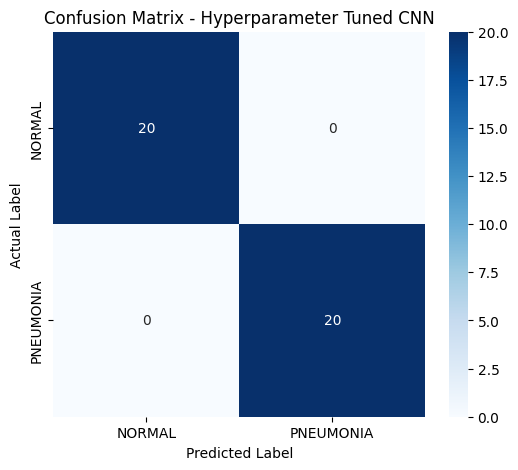

In [85]:
# Confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(
 cm, annot=True, fmt="d", cmap="Blues",
 xticklabels=["NORMAL", "PNEUMONIA"],
 yticklabels=["NORMAL", "PNEUMONIA"]
)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Hyperparameter Tuned CNN")
plt.show()


In [86]:
# Classification report
from sklearn.metrics import classification_report
print(classification_report(
 y_test,
 y_pred,
 target_names=["NORMAL", "PNEUMONIA"]
))

              precision    recall  f1-score   support

      NORMAL       1.00      1.00      1.00        20
   PNEUMONIA       1.00      1.00      1.00        20

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



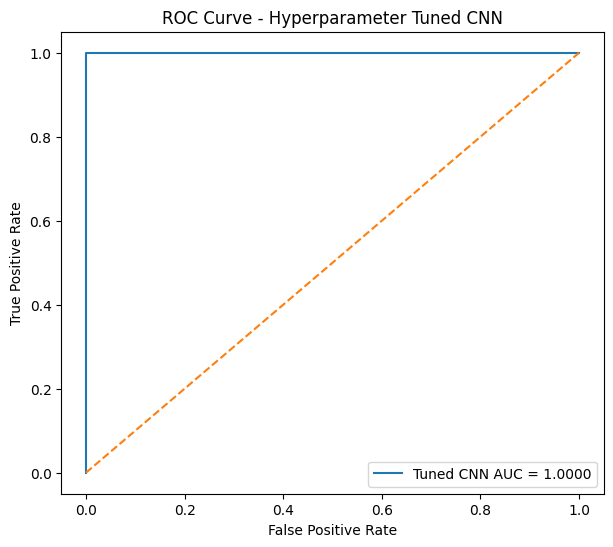

In [87]:
#  ROC curve and AUC
from sklearn.metrics import roc_curve, roc_auc_score
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
auc_score = roc_auc_score(y_test, y_pred_prob)
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"Tuned CNN AUC = {auc_score:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Hyperparameter Tuned CNN")
plt.legend()
plt.show()

# Model Evaluation and Testing- Gautham Hari

In [88]:


# 45. RESNET50 FINE-TUNING TRAINING


early_stop_finetune = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-7
)

finetune_history = transfer_model.fit(
    X_train_processed,
    y_train,
    validation_data=(X_val_processed, y_val),
    epochs=10,
    batch_size=16,
    callbacks=[early_stop_finetune, reduce_lr]
)


Epoch 1/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 219ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0053 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0096 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 5.0000e-06
Epoch 2/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 95ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0016 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0163 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 5.0000e-06
Epoch 3/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 95ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0022 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0116 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 5.0000e-06
Epoch 4/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 122ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 9.8172e-04 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0091

In [89]:


# 46. SAVE FINAL FINE-TUNED MODEL


transfer_model.save("resnet50_finetuned.keras")

print("Fine-tuned ResNet50 model saved successfully!")


Fine-tuned ResNet50 model saved successfully!


In [90]:


# 47. MODEL EVALUATION ON TEST DATA


test_results = transfer_model.evaluate(
    X_test_processed,
    y_test,
    batch_size=16,
    verbose=1
)

print("\nRESNET50 TEST RESULTS")

for metric_name, metric_value in zip(
    transfer_model.metrics_names,
    test_results
):
    print(f"{metric_name}: {metric_value:.4f}")


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0150 - precision: 1.0000 - recall: 1.0000

RESNET50 TEST RESULTS
loss: 0.0150
compile_metrics: 1.0000


In [91]:


# 48. PREDICT ON TEST DATA


y_pred_prob = transfer_model.predict(X_test_processed)

# Convert probabilities into binary predictions
y_pred = (y_pred_prob > 0.5).astype(int).flatten()

y_true = y_test.astype(int)

print("Predictions generated successfully!")

print("Actual labels:", y_true[:10])
print("Predicted labels:", y_pred[:10])
print("Prediction probabilities:", y_pred_prob[:10].flatten())


2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 437ms/step
Predictions generated successfully!
Actual labels: [0 0 0 0 0 0 0 0 0 0]
Predicted labels: [0 0 0 0 0 0 0 0 0 0]
Prediction probabilities: [5.2221931e-05 6.4746004e-05 4.5968653e-04 2.0846783e-03 2.0771520e-03
 5.9573315e-02 4.2557978e-04 5.7628513e-05 4.0106392e-05 9.9647741e-07]


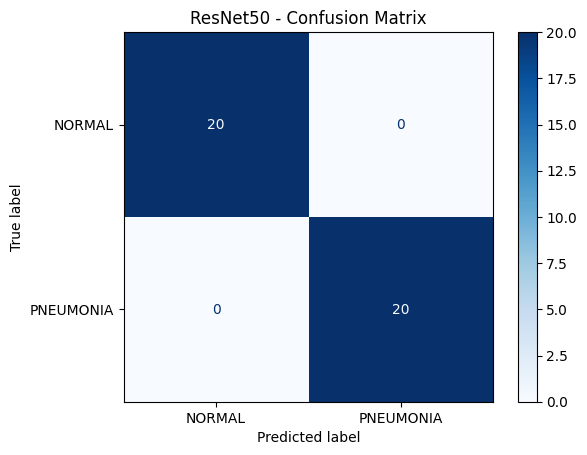

Confusion Matrix:
[[20  0]
 [ 0 20]]


In [92]:

# ==========================================
# 49. CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NORMAL", "PNEUMONIA"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("ResNet50 - Confusion Matrix")
plt.show()

print("Confusion Matrix:")
print(cm)


In [93]:

# ==========================================
# 50. CLASSIFICATION REPORT
# ==========================================

print("RESNET50 CLASSIFICATION REPORT")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=["NORMAL", "PNEUMONIA"],
        digits=4
    )
)


RESNET50 CLASSIFICATION REPORT
              precision    recall  f1-score   support

      NORMAL     1.0000    1.0000    1.0000        20
   PNEUMONIA     1.0000    1.0000    1.0000        20

    accuracy                         1.0000        40
   macro avg     1.0000    1.0000    1.0000        40
weighted avg     1.0000    1.0000    1.0000        40



In [94]:

# ==========================================
# 51. TEST DATASET INFORMATION
# ==========================================

print("Total test images:", len(y_test))

print("\nClass distribution:")

for i, name in enumerate(class_names):
    print(name, ":", np.sum(y_test == i))

print("\nCorrect predictions:", np.sum(y_true == y_pred))
print("Incorrect predictions:", np.sum(y_true != y_pred))


Total test images: 40

Class distribution:
NORMAL : 20
PNEUMONIA : 20

Correct predictions: 40
Incorrect predictions: 0


In [95]:

# ==========================================
# 55. CUSTOM CNN MODEL EVALUATION
# ==========================================

cnn_results = cnn_model.evaluate(
    X_test_processed,
    y_test,
    batch_size=16,
    verbose=1
)

print("\nCUSTOM CNN TEST RESULTS")

for name, value in zip(
    cnn_model.metrics_names,
    cnn_results
):
    print(f"{name}: {value:.4f}")


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.1972 - precision: 1.0000 - recall: 1.0000             

CUSTOM CNN TEST RESULTS
loss: 0.1972
compile_metrics: 1.0000


In [96]:

# ==========================================
# 56. CUSTOM CNN PREDICTIONS
# ==========================================

cnn_pred_prob = cnn_model.predict(X_test_processed)

cnn_pred = (cnn_pred_prob > 0.5).astype(int).flatten()

print("CNN predictions generated successfully!")

print("Actual labels:", y_test[:10])
print("Predicted labels:", cnn_pred[:10])


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
CNN predictions generated successfully!
Actual labels: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Predicted labels: [0 0 0 0 0 0 0 0 0 0]


In [97]:

# ==========================================
# 56. CUSTOM CNN PREDICTIONS
# ==========================================

cnn_pred_prob = cnn_model.predict(X_test_processed)

cnn_pred = (cnn_pred_prob > 0.5).astype(int).flatten()

print("CNN predictions generated successfully!")

print("Actual labels:", y_test[:10])
print("Predicted labels:", cnn_pred[:10])


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
CNN predictions generated successfully!
Actual labels: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Predicted labels: [0 0 0 0 0 0 0 0 0 0]


In [99]:

# ==========================================
# 57. CUSTOM CNN PERFORMANCE METRICS
# ==========================================

cnn_accuracy = accuracy_score(y_true, cnn_pred)

cnn_precision = precision_score(y_true, cnn_pred)
cnn_recall = recall_score(y_true, cnn_pred)
cnn_f1 = f1_score(y_true, cnn_pred)

cnn_auc = roc_auc_score(
    y_true,
    cnn_pred_prob.flatten()
)

print("CUSTOM CNN PERFORMANCE")
print("------------------------")
print(f"Accuracy  : {cnn_accuracy:.4f}")
print(f"Precision : {cnn_precision:.4f}")
print(f"Recall    : {cnn_recall:.4f}")
print(f"F1 Score  : {cnn_f1:.4f}")
print(f"AUC Score : {cnn_auc:.4f}")


CUSTOM CNN PERFORMANCE
------------------------
Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1 Score  : 1.0000
AUC Score : 1.0000


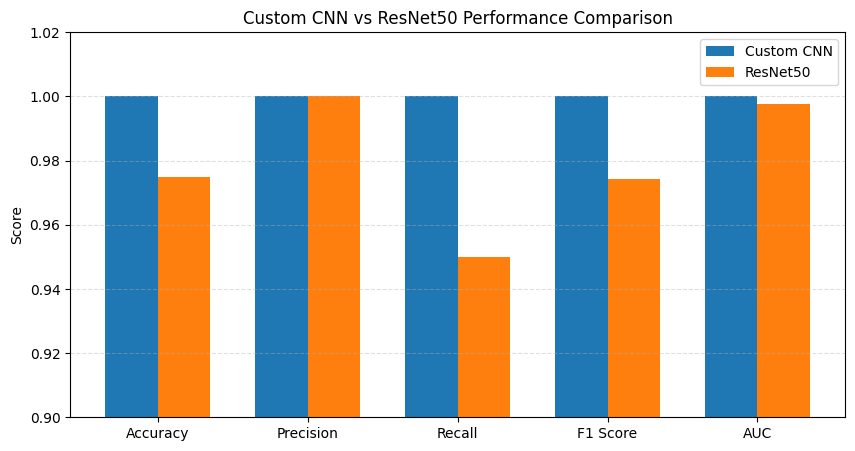

In [100]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'AUC']

cnn_scores = [
    cnn_accuracy,
    cnn_precision,
    cnn_recall,
    cnn_f1,
    cnn_auc
]

resnet_scores = [
    0.9750,
    1.0000,
    0.9500,
    0.9744,
    0.9975
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(x - width/2, cnn_scores, width, label='Custom CNN')
plt.bar(x + width/2, resnet_scores, width, label='ResNet50')

plt.ylabel('Score')
plt.title('Custom CNN vs ResNet50 Performance Comparison')
plt.xticks(x, metrics)
plt.ylim(0.90, 1.02)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.show()

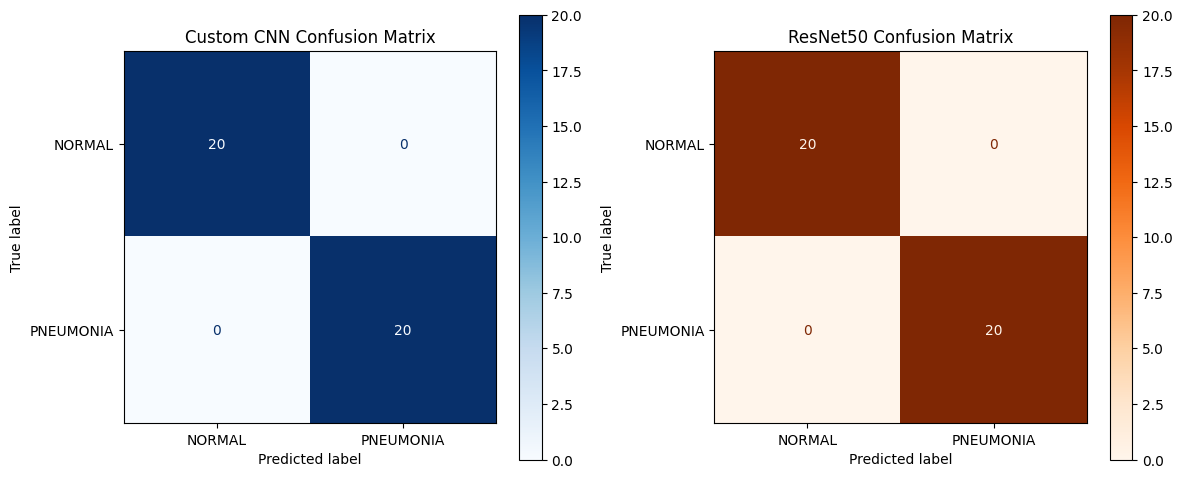

In [101]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate confusion matrices
cm_cnn = confusion_matrix(y_true, cnn_pred)
cm_resnet = confusion_matrix(y_true, y_pred)

# Plot side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm_cnn,
    display_labels=['NORMAL', 'PNEUMONIA']
).plot(ax=axes[0], cmap='Blues', values_format='d')

axes[0].set_title('Custom CNN Confusion Matrix')

ConfusionMatrixDisplay(
    confusion_matrix=cm_resnet,
    display_labels=['NORMAL', 'PNEUMONIA']
).plot(ax=axes[1], cmap='Oranges', values_format='d')

axes[1].set_title('ResNet50 Confusion Matrix')

plt.tight_layout()
plt.show()

In [102]:
from sklearn.metrics import classification_report

print("========== CUSTOM CNN ==========")
print(classification_report(
    y_true,
    cnn_pred,
    target_names=['NORMAL', 'PNEUMONIA']
))

print("========== RESNET50 ==========")
print(classification_report(
    y_true,
    y_pred,
    target_names=['NORMAL', 'PNEUMONIA']
))

========== CUSTOM CNN ==========
              precision    recall  f1-score   support

      NORMAL       1.00      1.00      1.00        20
   PNEUMONIA       1.00      1.00      1.00        20

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40

========== RESNET50 ==========
              precision    recall  f1-score   support

      NORMAL       1.00      1.00      1.00        20
   PNEUMONIA       1.00      1.00      1.00        20

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



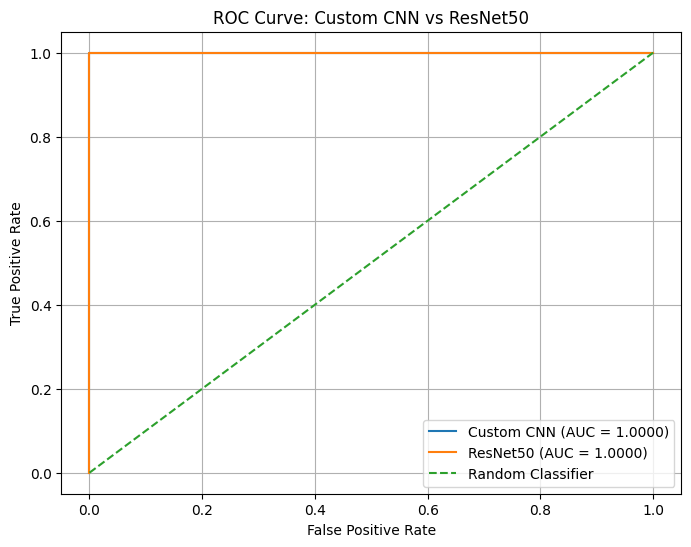

In [103]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Calculate ROC curves
fpr_cnn, tpr_cnn, _ = roc_curve(
    y_true, cnn_pred_prob.flatten()
)

fpr_resnet, tpr_resnet, _ = roc_curve(
    y_true, y_pred_prob.flatten()
)

auc_cnn = auc(fpr_cnn, tpr_cnn)
auc_resnet = auc(fpr_resnet, tpr_resnet)

# Plot
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_cnn, tpr_cnn,
    label=f'Custom CNN (AUC = {auc_cnn:.4f})'
)

plt.plot(
    fpr_resnet, tpr_resnet,
    label=f'ResNet50 (AUC = {auc_resnet:.4f})'
)

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve: Custom CNN vs ResNet50')
plt.legend()
plt.grid()
plt.show()

In [104]:
# Saving the best model
cnn_model.save("custom_cnn_model.keras")


print("Model saved successfully!")

Model saved successfully!


In [105]:
# ==========================================
# CUSTOM CNN ARCHITECTURE CHECK
# ==========================================

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 327,941 (1.25 MB)

 Trainable params: 109,313 (427.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 218,628 (854.02 KB)